# Expedia Case Demo 1

## Part A: Cleaning and Analysing Data

### 1. Introduction

### 2. Data Preparation & Analysis

#### (1) Load Libraries

In [24]:
library(tidyverse)   # data wrangling and visualization
library(scales)      # formatting axis labels (e.g., percent)
library(patchwork)   # combining multiple plots
library(ggokabeito)  # colour-blind-friendly palette (course default)
library(recipes)     # scaling
library(cluster)     # K-means
library(factoextra)  # K-mean visualization

#### (2) Load Data

In [25]:
expedia <- read_csv("data/expedia.csv") 

# Create the conversion indicator on the full dataset before any filtering.
# converted = 1: user clicked AND booked (successful conversion)
# converted = 0: user clicked but did NOT book (failed conversion)
# converted = NA: user never clicked (conversion is not applicable)
expedia <- expedia |>
  mutate(
    converted = case_when(
      click_bool == 1 & booking_bool == 1 ~ 1,
      click_bool == 1 & booking_bool == 0 ~ 0,
      .default                            = NA
    )
  )

Rows: 158269 Columns: 54
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (31): visitor_hist_starrating, visitor_hist_adr_usd, prop_review_score,...
dbl  (22): srch_id, site_id, visitor_location_country_id, prop_country_id, p...
date  (1): date_time

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [26]:
# Quick preview of the raw dataset
expedia |> slice_head(n = 10)

srch_id,date_time,site_id,visitor_location_country_id,visitor_hist_starrating,visitor_hist_adr_usd,prop_country_id,prop_id,prop_starrating,prop_review_score,⋯,comp7_rate,comp7_inv,comp7_rate_percent_diff,comp8_rate,comp8_inv,comp8_rate_percent_diff,click_bool,gross_bookings_usd,booking_bool,converted
<dbl>,<date>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
61,2013-06-22,5,219,NULL,NULL,219,16517,3,4.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,31767,2,3.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,39799,2,3.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,68629,2,2.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,73060,3,3.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,78003,3,4.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,107306,3,3.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,123254,3,4.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA
61,2013-06-22,5,219,NULL,NULL,219,124295,3,3.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,0,NULL,0,NA


#### (3) Data Cleaning

In [27]:
# Inspect the distribution of the four continuous variables we will clean
# This helps us identify the extent of extreme values before filtering
expedia |>
  select(srch_length_of_stay, srch_adults_count, srch_booking_window, price_usd) |>
  summary()

 srch_length_of_stay srch_adults_count srch_booking_window   price_usd      
 Min.   : 1.000      Min.   :1.000     Min.   :  0.00      Min.   :   13.0  
 1st Qu.: 1.000      1st Qu.:2.000     1st Qu.:  3.00      1st Qu.:   88.0  
 Median : 2.000      Median :2.000     Median : 11.00      Median :  122.0  
 Mean   : 2.049      Mean   :2.023     Mean   : 22.71      Mean   :  153.1  
 3rd Qu.: 3.000      3rd Qu.:2.000     3rd Qu.: 28.00      3rd Qu.:  179.0  
 Max.   :24.000      Max.   :9.000     Max.   :472.00      Max.   :58642.0  

In [28]:
# Check the share of non-clicked rows and the resulting proportion of missing converted values
# We also verify how many listings have an extreme price above $500
expedia |>
  summarise(
    n_total            = n(),
    n_non_click        = sum(click_bool == 0),
    p_non_click        = n_non_click / n_total,
    n_na_convert       = sum(is.na(converted)),
    p_na_convert       = n_na_convert / n_total,
  )

n_total,n_non_click,p_non_click,n_na_convert,p_na_convert
<int>,<int>,<dbl>,<int>,<dbl>
158269,151393,0.956555,151393,0.956555


In [29]:
# Apply all cleaning filters in one step:
# - Trim the top 10% of srch_length_of_stay, srch_adults_count, and srch_booking_window
# - Remove hotels priced above $500
# - Keep only clicked listings (i.e., rows where converted is not NA)
expedia_clean <- expedia |>
  filter(
    srch_length_of_stay <= quantile(srch_length_of_stay, 0.90),
    srch_adults_count   <= quantile(srch_adults_count, 0.90),
    srch_booking_window <= quantile(srch_booking_window, 0.90),
    price_usd <= 500,
    !is.na(converted)
  )

In [30]:
# Spot-check the cleaned dataset
expedia_clean |> slice_head(n = 10)

srch_id,date_time,site_id,visitor_location_country_id,visitor_hist_starrating,visitor_hist_adr_usd,prop_country_id,prop_id,prop_starrating,prop_review_score,⋯,comp7_rate,comp7_inv,comp7_rate_percent_diff,comp8_rate,comp8_inv,comp8_rate_percent_diff,click_bool,gross_bookings_usd,booking_bool,converted
<dbl>,<date>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>
81,2013-06-25,5,219,NULL,NULL,219,103860,2,3.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,1,NULL,0,0
106,2013-06-17,5,219,NULL,NULL,219,39675,3,4.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,1,171.64,1,1
106,2013-06-17,5,219,NULL,NULL,219,112905,2,0.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,1,NULL,0,0
118,2013-06-17,5,219,NULL,NULL,219,86727,3,4.5,⋯,NULL,NULL,NULL,0,0,NULL,1,439.77,1,1
180,2013-06-29,5,219,NULL,NULL,219,96068,2,3.5,⋯,NULL,NULL,NULL,0,0,NULL,1,NULL,0,0
242,2013-06-04,5,219,NULL,NULL,219,17690,2,2.5,⋯,NULL,NULL,NULL,NULL,NULL,NULL,1,120.12,1,1
297,2013-06-04,5,219,NULL,NULL,219,38088,2,3.0,⋯,NULL,NULL,NULL,-1,0,5,1,385.72,1,1
322,2013-06-18,5,219,NULL,NULL,219,118456,3,4.0,⋯,NULL,NULL,NULL,NULL,NULL,NULL,1,161.06,1,1
325,2013-06-03,5,219,NULL,NULL,219,41261,3,3.0,⋯,NULL,NULL,NULL,-1,0,5,1,149.86,1,1


#### (4) Data Processing

In [31]:
# Create derived categorical variables for use in grouping and visualisation
expedia_clean <- expedia_clean |>
  mutate(
    # Collapse continuous review score into four ordered bands
    review_group = case_when(
      prop_review_score < 3.0                            ~ "Low (below 3.0)",
      prop_review_score >= 3.0 & prop_review_score < 4.0 ~ "Medium (3.0–3.9)",
      prop_review_score >= 4.0 & prop_review_score < 4.5 ~ "Good (4.0–4.4)",
      prop_review_score >= 4.5                           ~ "Excellent (4.5–5.0)"
    ),
    star_label = case_when(
      prop_starrating == 0 ~ "Unrated",
      prop_starrating == 1 ~ "1 Star",
      prop_starrating == 2 ~ "2 Stars",
      prop_starrating == 3 ~ "3 Stars",
      prop_starrating == 4 ~ "4 Stars",
      prop_starrating == 5 ~ "5 Stars",
    )
  )

In [32]:
# Encode all categorical variables as ordered factors
# This ensures plots and tables display groups in a meaningful sequence
expedia_clean <- expedia_clean |>
  mutate(
    review_group = factor(
      review_group,
      levels = c(
        "Low (below 3.0)", 
        "Medium (3.0–3.9)", 
        "Good (4.0–4.4)", 
        "Excellent (4.5–5.0)"
        )
    ),
    star_label = factor(
      star_label,
      levels = c(
        "Unrated", 
        "1 Star", 
        "2 Stars", 
        "3 Stars", 
        "4 Stars", 
        "5 Stars"
        )
    )
  )

In [33]:
# Select only the columns used in this analysis
# Dropping unused columns reduces clutter and makes downstream code easier to follow
expedia_clean <- expedia_clean |>
  select(
    # Hotel and search identifiers
    prop_id,
    srch_id,          # used to sort by recency when computing last price
    
    # Hotel attributes
    prop_starrating,
    prop_review_score,
    price_usd,
    promotion_flag,
    
    # Search behaviour
    position,
    srch_length_of_stay,
    srch_adults_count,
    srch_booking_window,
    
    # Outcome variables
    click_bool,
    booking_bool,
    converted
  )

In [34]:
expedia_clean |> slice_head(n = 10)

prop_id,srch_id,prop_starrating,prop_review_score,price_usd,promotion_flag,position,srch_length_of_stay,srch_adults_count,srch_booking_window,click_bool,booking_bool,converted
<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
103860,81,2,3.0,92,0,23,1,2,3,1,0,0
39675,106,3,4.5,180,1,2,1,2,24,1,1,1
112905,106,2,0.0,183,0,7,1,2,24,1,0,0
86727,118,3,4.5,99,0,21,3,2,31,1,1,1
96068,180,2,3.5,109,0,10,3,2,1,1,0,0
17690,242,2,2.5,53,1,18,2,2,12,1,1,1
38088,297,2,3.0,167,0,2,2,1,10,1,1,1
118456,322,3,4.0,156,1,2,1,2,31,1,1,1
41261,325,3,3.0,134,0,7,1,2,12,1,1,1


In [35]:
# Step 1: Compute click rate from the full dataset (price-filtered but NOT click-filtered)
# Using the full data here is critical: click_rate = clicks / impressions,
# so non-clicked rows must be included in the denominator
hotel_click_rate <- expedia |>
  filter(price_usd <= 500) |> 
  group_by(prop_id) |>
  summarise(
    n_shown    = n(),
    click_rate = mean(click_bool),
  ) |>
  ungroup()

# Step 2: Compute conversion rate and search-level averages from clicked listings only
# last_price uses the most recent search (sorted by srch_id) as a proxy for current price
hotel_conv_rate <-
  expedia_clean |>
  arrange(srch_id) |>
  group_by(prop_id) |>
  summarise(
    n_clicked          = n(),
    conversion_rate    = mean(converted, na.rm = TRUE),
    last_price         = last(price_usd),          # most recent observed price
    avg_length_stay    = mean(srch_length_of_stay, na.rm = TRUE),
    avg_adults         = mean(srch_adults_count, na.rm = TRUE),
    avg_booking_window = mean(srch_booking_window, na.rm = TRUE),
  ) |>
  ungroup()

# Step 3: Join the two hotel-level summaries
# Keep only hotels with at least 3 clicks to ensure conversion rate estimates are stable
hotel_clean <-
  hotel_click_rate |>
  inner_join(hotel_conv_rate, by = "prop_id") |>
  filter(
    n_clicked >= 3
  )

# Step 4: Verify the range of key variables in hotel_clean
hotel_clean |>
  summarise(
    n_hotels   = n(),
    click_min  = min(click_rate),
    click_max  = max(click_rate),
    conv_min   = min(conversion_rate),
    conv_max   = max(conversion_rate),
    price_min  = min(last_price),
    price_max  = max(last_price)
  )

n_hotels,click_min,click_max,conv_min,conv_max,price_min,price_max
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
207,0.03225806,0.8333333,0,1,28,389


### 3. Data Analysis

#### (1) Summary of Conversion Rate

In [36]:
# Compute the overall conversion rate as a benchmark for all subsequent comparisons
overall_cvr <- expedia_clean |>
  summarise(
    n_clicked       = n(),
    n_converted     = sum(converted == 1, na.rm = TRUE),
    n_not_converted = sum(converted == 0, na.rm = TRUE),
    conversion_rate = mean(converted, na.rm = TRUE)
  )

overall_cvr

n_clicked,n_converted,n_not_converted,conversion_rate
<int>,<int>,<int>,<dbl>
5485,3710,1775,0.6763902


#### (2) Conversion Rate vs Star Rating & Review Score

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by prop_starrating and prop_review_score.
ℹ Output is grouped by prop_starrating.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(prop_starrating, prop_review_score))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.


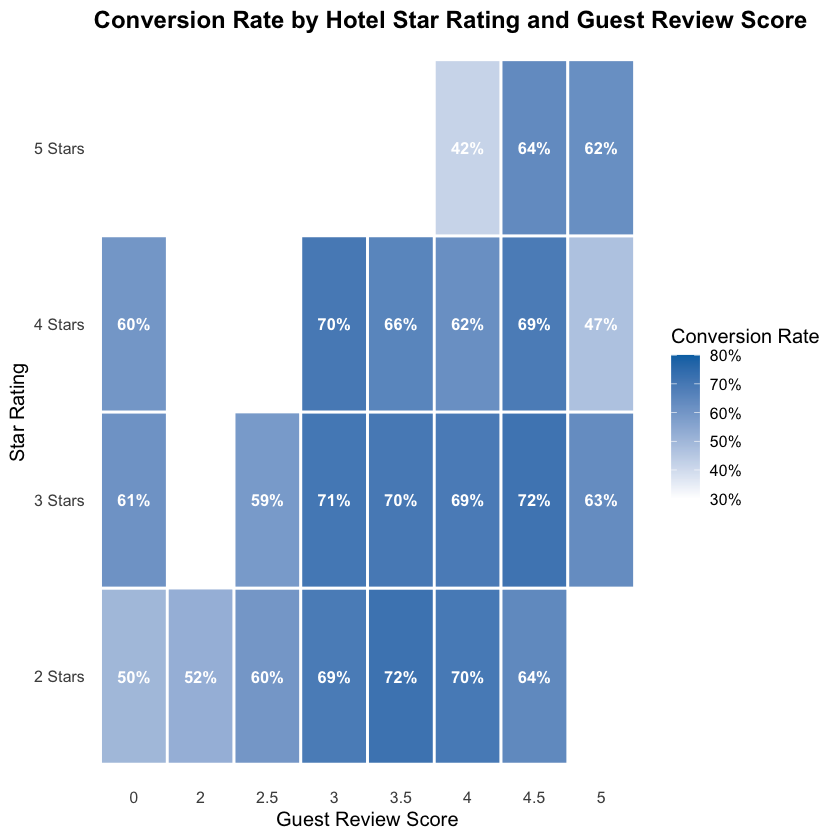

In [37]:
# Compute conversion rate for each star × review score combination
# Restrict to 2–5 stars (unrated and 1-star have too few observations)
# Filter to cells with at least 10 clicked listings for reliable estimates
cvr_star_review <-
  expedia_clean |>
  filter(prop_starrating %in% 2:5) |>
  group_by(prop_starrating, prop_review_score) |>
  summarise(
    n_clicked       = n(),
    conversion_rate = mean(converted, na.rm = TRUE),
  ) |> 
  ungroup() |>
  filter(n_clicked >= 10) |>
  mutate(
    # as.numeric() prevents ggplot from treating the grouping variable as a factor,
    # which would cause a "discrete value supplied to continuous scale" error
    prop_review_score = as.numeric(prop_review_score),
    star_label        = factor(
      prop_starrating,
      levels = 2:5,
      labels = c("2 Stars", "3 Stars", "4 Stars", "5 Stars")
    )
  )

plot_heatmap <-
  cvr_star_review |>
  ggplot(aes(x = factor(prop_review_score), y = star_label, fill = conversion_rate)) +
  geom_tile(colour = "white", linewidth = 0.8) +
  geom_text(
    aes(label = percent(conversion_rate, accuracy = 1)),
    size     = 3.5,
    colour   = "white",
    fontface = "bold"
  ) +
  scale_fill_gradient(
    low    = "white",
    high   = palette_okabe_ito()[5],
    limits = c(0.3, 0.8),
    labels = percent_format(accuracy = 1),
    name   = "Conversion Rate"
  ) +
  labs(
    title    = "Conversion Rate by Hotel Star Rating and Guest Review Score",
    x        = "Guest Review Score",
    y        = "Star Rating",
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title      = element_text(face = "bold"),
    plot.subtitle   = element_text(colour = "grey40"),
    panel.grid      = element_blank(),
    axis.ticks      = element_blank(),
    legend.position = "right"
  )

plot_heatmap

#### (3) Conversion Rate vs Journey Type

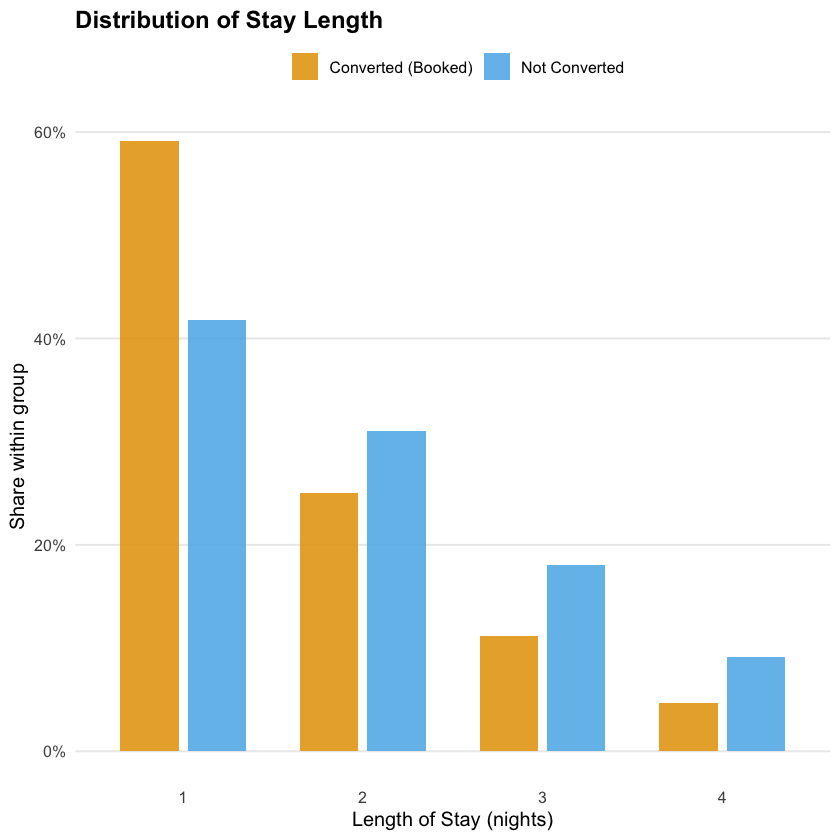

In [38]:
# Length of stay: grouped proportional bar chart
# after_stat(prop) normalises each outcome group to sum to 1,
# making the two groups directly comparable despite their different sizes
plot_los <- expedia_clean |>
  mutate(
    outcome = if_else(converted == 1, "Converted (Booked)", "Not Converted"),
    outcome = factor(outcome, levels = c("Converted (Booked)", "Not Converted"))
  ) |>
  ggplot(aes(x = factor(srch_length_of_stay),
             y = after_stat(prop),
             fill = outcome,
             group = outcome)) +
  geom_bar(position = position_dodge(width = 0.75),
           width = 0.65, alpha = 0.85) +
  scale_y_continuous(labels = percent_format(accuracy = 1)) +
  scale_fill_okabe_ito(name = "") +
  labs(
    title    = "Distribution of Stay Length",
    x        = "Length of Stay (nights)",
    y        = "Share within group",
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title       = element_text(face = "bold"),
    plot.subtitle    = element_text(colour = "grey40"),
    legend.position  = "top",
    panel.grid.major.x = element_blank(),
    panel.grid.minor   = element_blank()
  )

plot_los

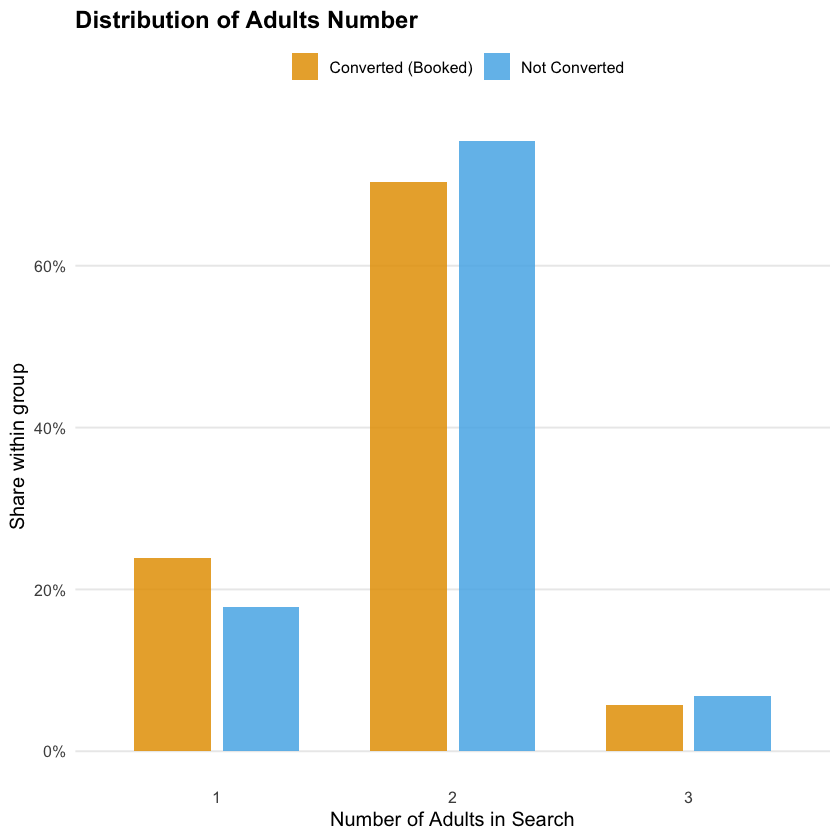

In [39]:
# Party size: same proportional bar chart approach as length of stay
plot_adults <- expedia_clean |>
  mutate(
    outcome = if_else(converted == 1, "Converted (Booked)", "Not Converted"),
    outcome = factor(outcome, levels = c("Converted (Booked)", "Not Converted"))
  ) |>
  ggplot(aes(x = factor(srch_adults_count),
             y = after_stat(prop),
             fill = outcome,
             group = outcome)) +
  geom_bar(position = position_dodge(width = 0.75),
           width = 0.65, alpha = 0.85) +
  scale_y_continuous(labels = percent_format(accuracy = 1)) +
  scale_fill_okabe_ito(name = "") +
  labs(
    title    = "Distribution of Adults Number",
    x        = "Number of Adults in Search",
    y        = "Share within group",
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(face = "bold"),
    plot.subtitle      = element_text(colour = "grey40"),
    legend.position    = "top",
    panel.grid.major.x = element_blank(),
    panel.grid.minor   = element_blank()
  )

plot_adults

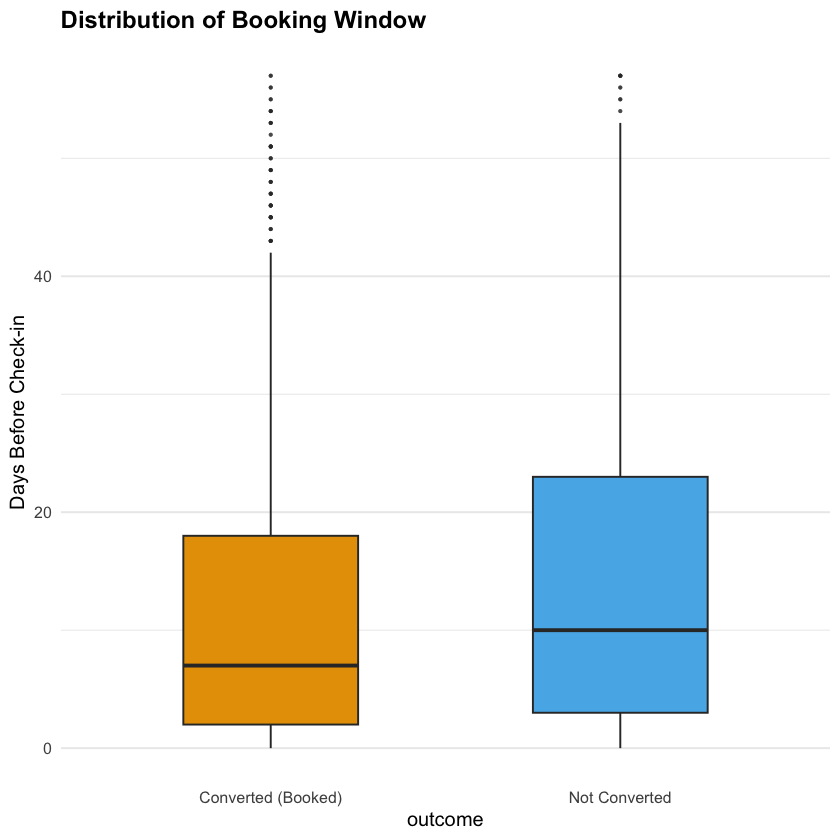

In [40]:
# Booking window: box plot to show the spread of a continuous variable
# Filtered to srch_booking_window < 62 to focus on the bulk of observations
# and avoid the x-axis being distorted by a small number of very large values
plot_window <- expedia_clean |>
  mutate(
    outcome = if_else(converted == 1, "Converted (Booked)", "Not Converted"),
    outcome = factor(outcome, levels = c("Converted (Booked)", "Not Converted"))
  ) |>
  filter(
    srch_booking_window < 62
  ) |>
  ggplot(aes(x = outcome, y = srch_booking_window, fill = outcome)) +
  geom_boxplot(
    width         = 0.5,
    outlier.shape = 16,
    outlier.size  = 0.8,
    outlier.alpha = 0.3,
    show.legend   = FALSE
  ) +
  scale_fill_okabe_ito() +
  scale_y_continuous(labels = comma) +
  labs(
    title    = "Distribution of Booking Window",
    y        = "Days Before Check-in",
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title         = element_text(face = "bold"),
    plot.subtitle      = element_text(colour = "grey40"),
    panel.grid.major.x = element_blank()
  )

plot_window

#### (4) Conversion Rate vs Hotel Price 

`geom_smooth()` using formula = 'y ~ x'


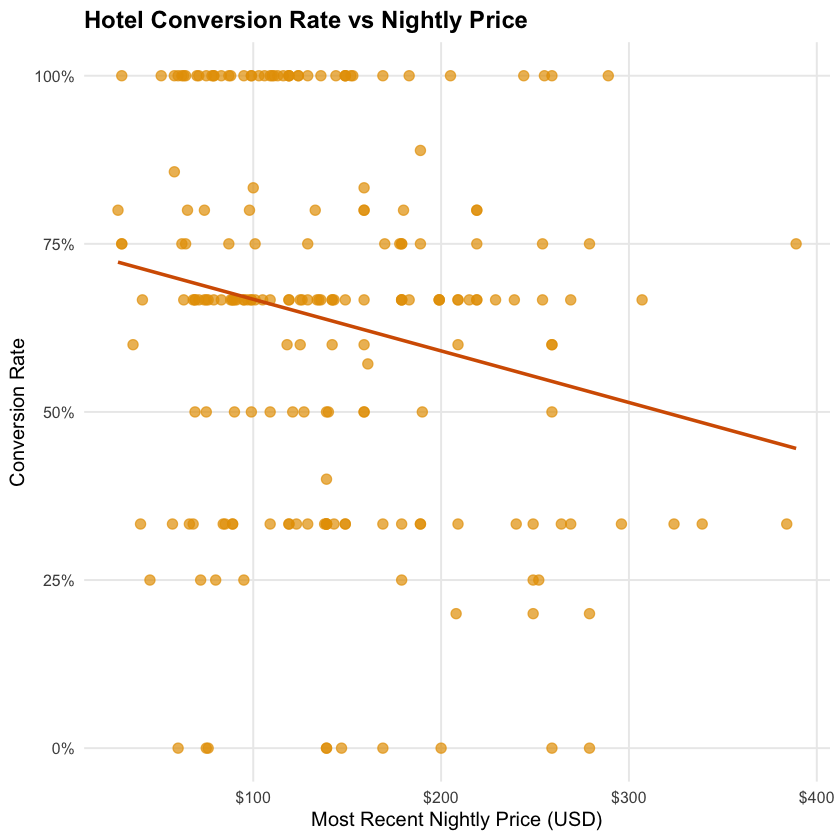

In [41]:
# Scatter plot: hotel-level conversion rate vs most recent nightly price
# Each point represents one hotel; the OLS line summarises the overall trend
plot_price <- hotel_clean |>
  ggplot(aes(x = last_price, y = conversion_rate)) +
  geom_point(
    colour = palette_okabe_ito()[1],
    size   = 2.5,
    alpha  = 0.7
  ) +
  geom_smooth(
    method    = "lm",
    se        = FALSE,
    colour    = palette_okabe_ito()[6],
    linewidth = 1
  ) +
  scale_x_continuous(labels = dollar_format()) +
  scale_y_continuous(labels = percent_format(accuracy = 1)) +
  labs(
    title    = "Hotel Conversion Rate vs Nightly Price",
    x        = "Most Recent Nightly Price (USD)",
    y        = "Conversion Rate",
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title       = element_text(face = "bold"),
    plot.subtitle    = element_text(colour = "grey40"),
    panel.grid.minor = element_blank()
  )

plot_price

#### (5) K-Means Clustering of Hotels

In [42]:
# Extract the two clustering features from hotel_clean
# Standardisation via recipe ensures click_rate and conversion_rate
# contribute equally to the k-means distance calculation
df_kmeans <- hotel_clean |>
  select(click_rate, conversion_rate)

rec <- recipe(~ ., data = df_kmeans) |>
  step_normalize(all_numeric_predictors())

df_scaled <- rec |>
  prep() |>
  bake(new_data = NULL)

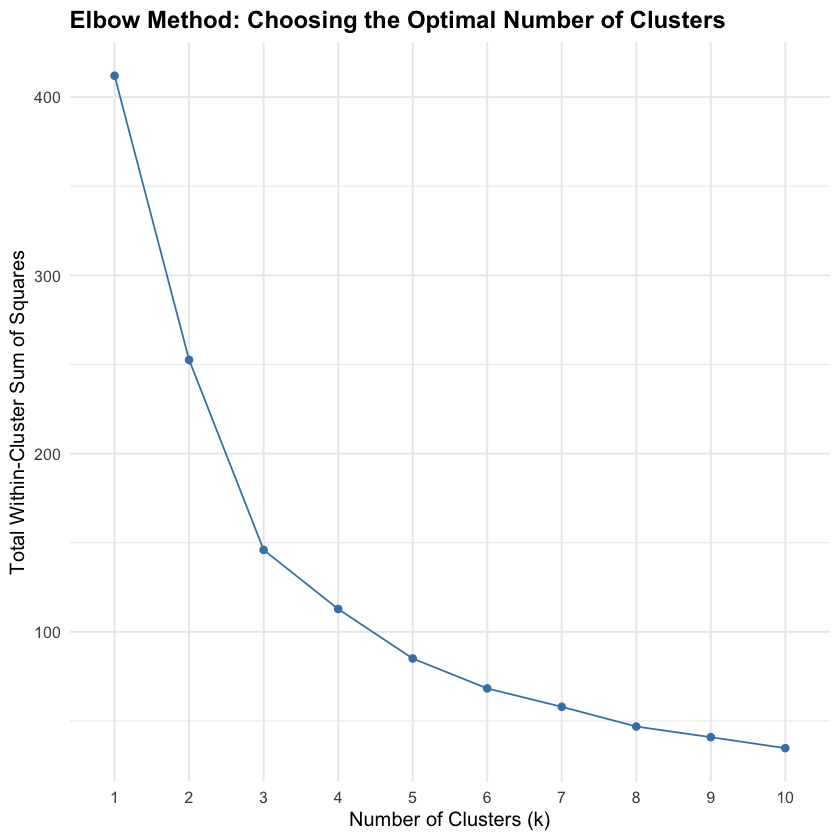

In [43]:
# Elbow method: plot total within-cluster sum of squares for k = 1 to 10
# The optimal k is where the curve bends — adding more clusters yields diminishing returns
fviz_nbclust(df_scaled, kmeans, method = "wss", k.max  = 10, nstart = 10) +
  labs(
    title    = "Elbow Method: Choosing the Optimal Number of Clusters",
    x        = "Number of Clusters (k)",
    y        = "Total Within-Cluster Sum of Squares"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title    = element_text(face = "bold"),
    plot.subtitle = element_text(colour = "grey40")
  )

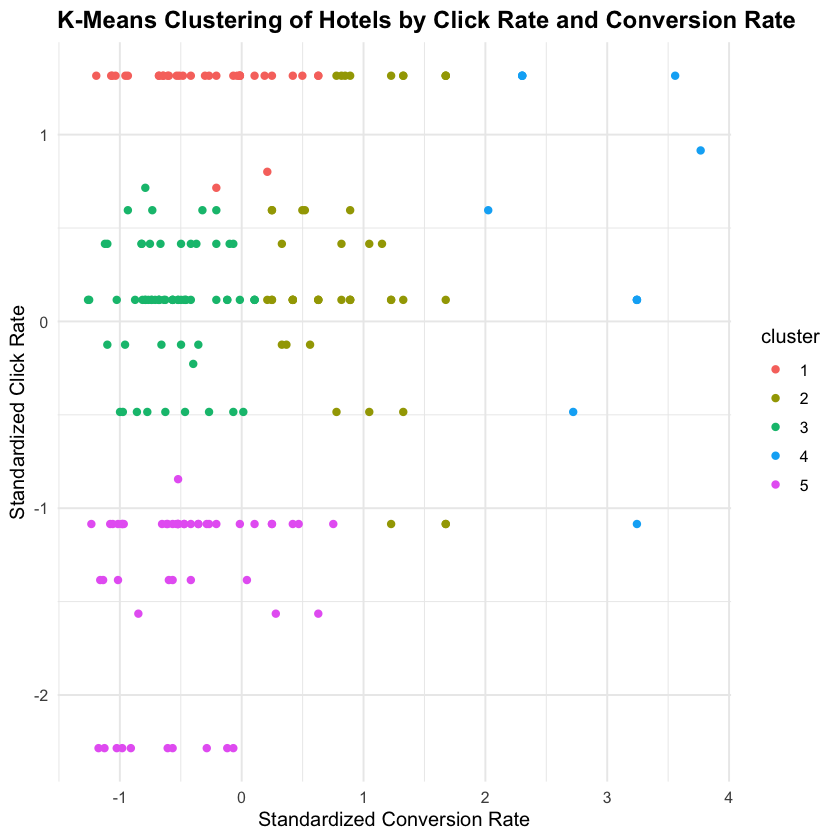

In [44]:
set.seed(123)

kmeans_hotels <- kmeans(df_scaled, centers = 5, nstart  = 2)

# Visualise the cluster assignments in standardised feature space
plot_kmeans <- fviz_cluster(
  kmeans_hotels,
  data        = df_scaled,
  geom        = "point",       # show points only — no labels, no ellipses
  shape       = 16,            # uniform solid circle for all clusters
  pointsize   = 2,
  ellipse     = FALSE,         # suppress confidence ellipses for a cleaner plot
  show.clust.cent = FALSE,     # suppress centroid markers
  ggtheme     = theme_minimal(),
) + 
  labs(
    title    = "K-Means Clustering of Hotels by Click Rate and Conversion Rate",
    x        = "Standardized Conversion Rate",
    y        = "Standardized Click Rate"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    plot.title    = element_text(face = "bold"),
    plot.subtitle = element_text(colour = "grey40")
  )

plot_kmeans

In [45]:
# Attach cluster labels back to the original (unstandardised) hotel data
# Then summarise each cluster's average characteristics for interpretation
hotel_clustered <-
  hotel_clean |>
  mutate(cluster = as.factor(kmeans_hotels$cluster))

# Summary table: sorted by descending average conversion rate so the
# highest-converting cluster appears at the top
hotel_summary<- hotel_clustered |>
  group_by(cluster) |>
  summarise(
    n_hotels           = n(),
    avg_click_rate     = mean(click_rate),
    avg_conv_rate      = mean(conversion_rate),
    avg_price          = mean(last_price),
    avg_length_stay    = mean(avg_length_stay),
    avg_adults         = mean(avg_adults),
    avg_booking_window = mean(avg_booking_window),
    avg_n_shown        = mean(n_shown),
  ) |> 
  ungroup() |>
  arrange(desc(avg_conv_rate))

hotel_summary

cluster,n_hotels,avg_click_rate,avg_conv_rate,avg_price,avg_length_stay,avg_adults,avg_booking_window,avg_n_shown
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,34,0.1850187,0.9908964,129.7647,1.689426,1.782353,12.46835,27.382353
4,11,0.6959596,0.7747475,108.4545,1.520202,1.782828,11.64192,5.727273
2,46,0.3723671,0.7239130,117.2609,1.749120,1.867184,12.80714,11.695652
3,65,0.1420029,0.6631502,152.8154,1.874249,1.892967,13.31245,37.676923
5,51,0.1561644,0.2500000,169.4314,2.002614,1.867320,14.29444,33.686275


### 4. Data Analysis Summary

`geom_smooth()` using formula = 'y ~ x'


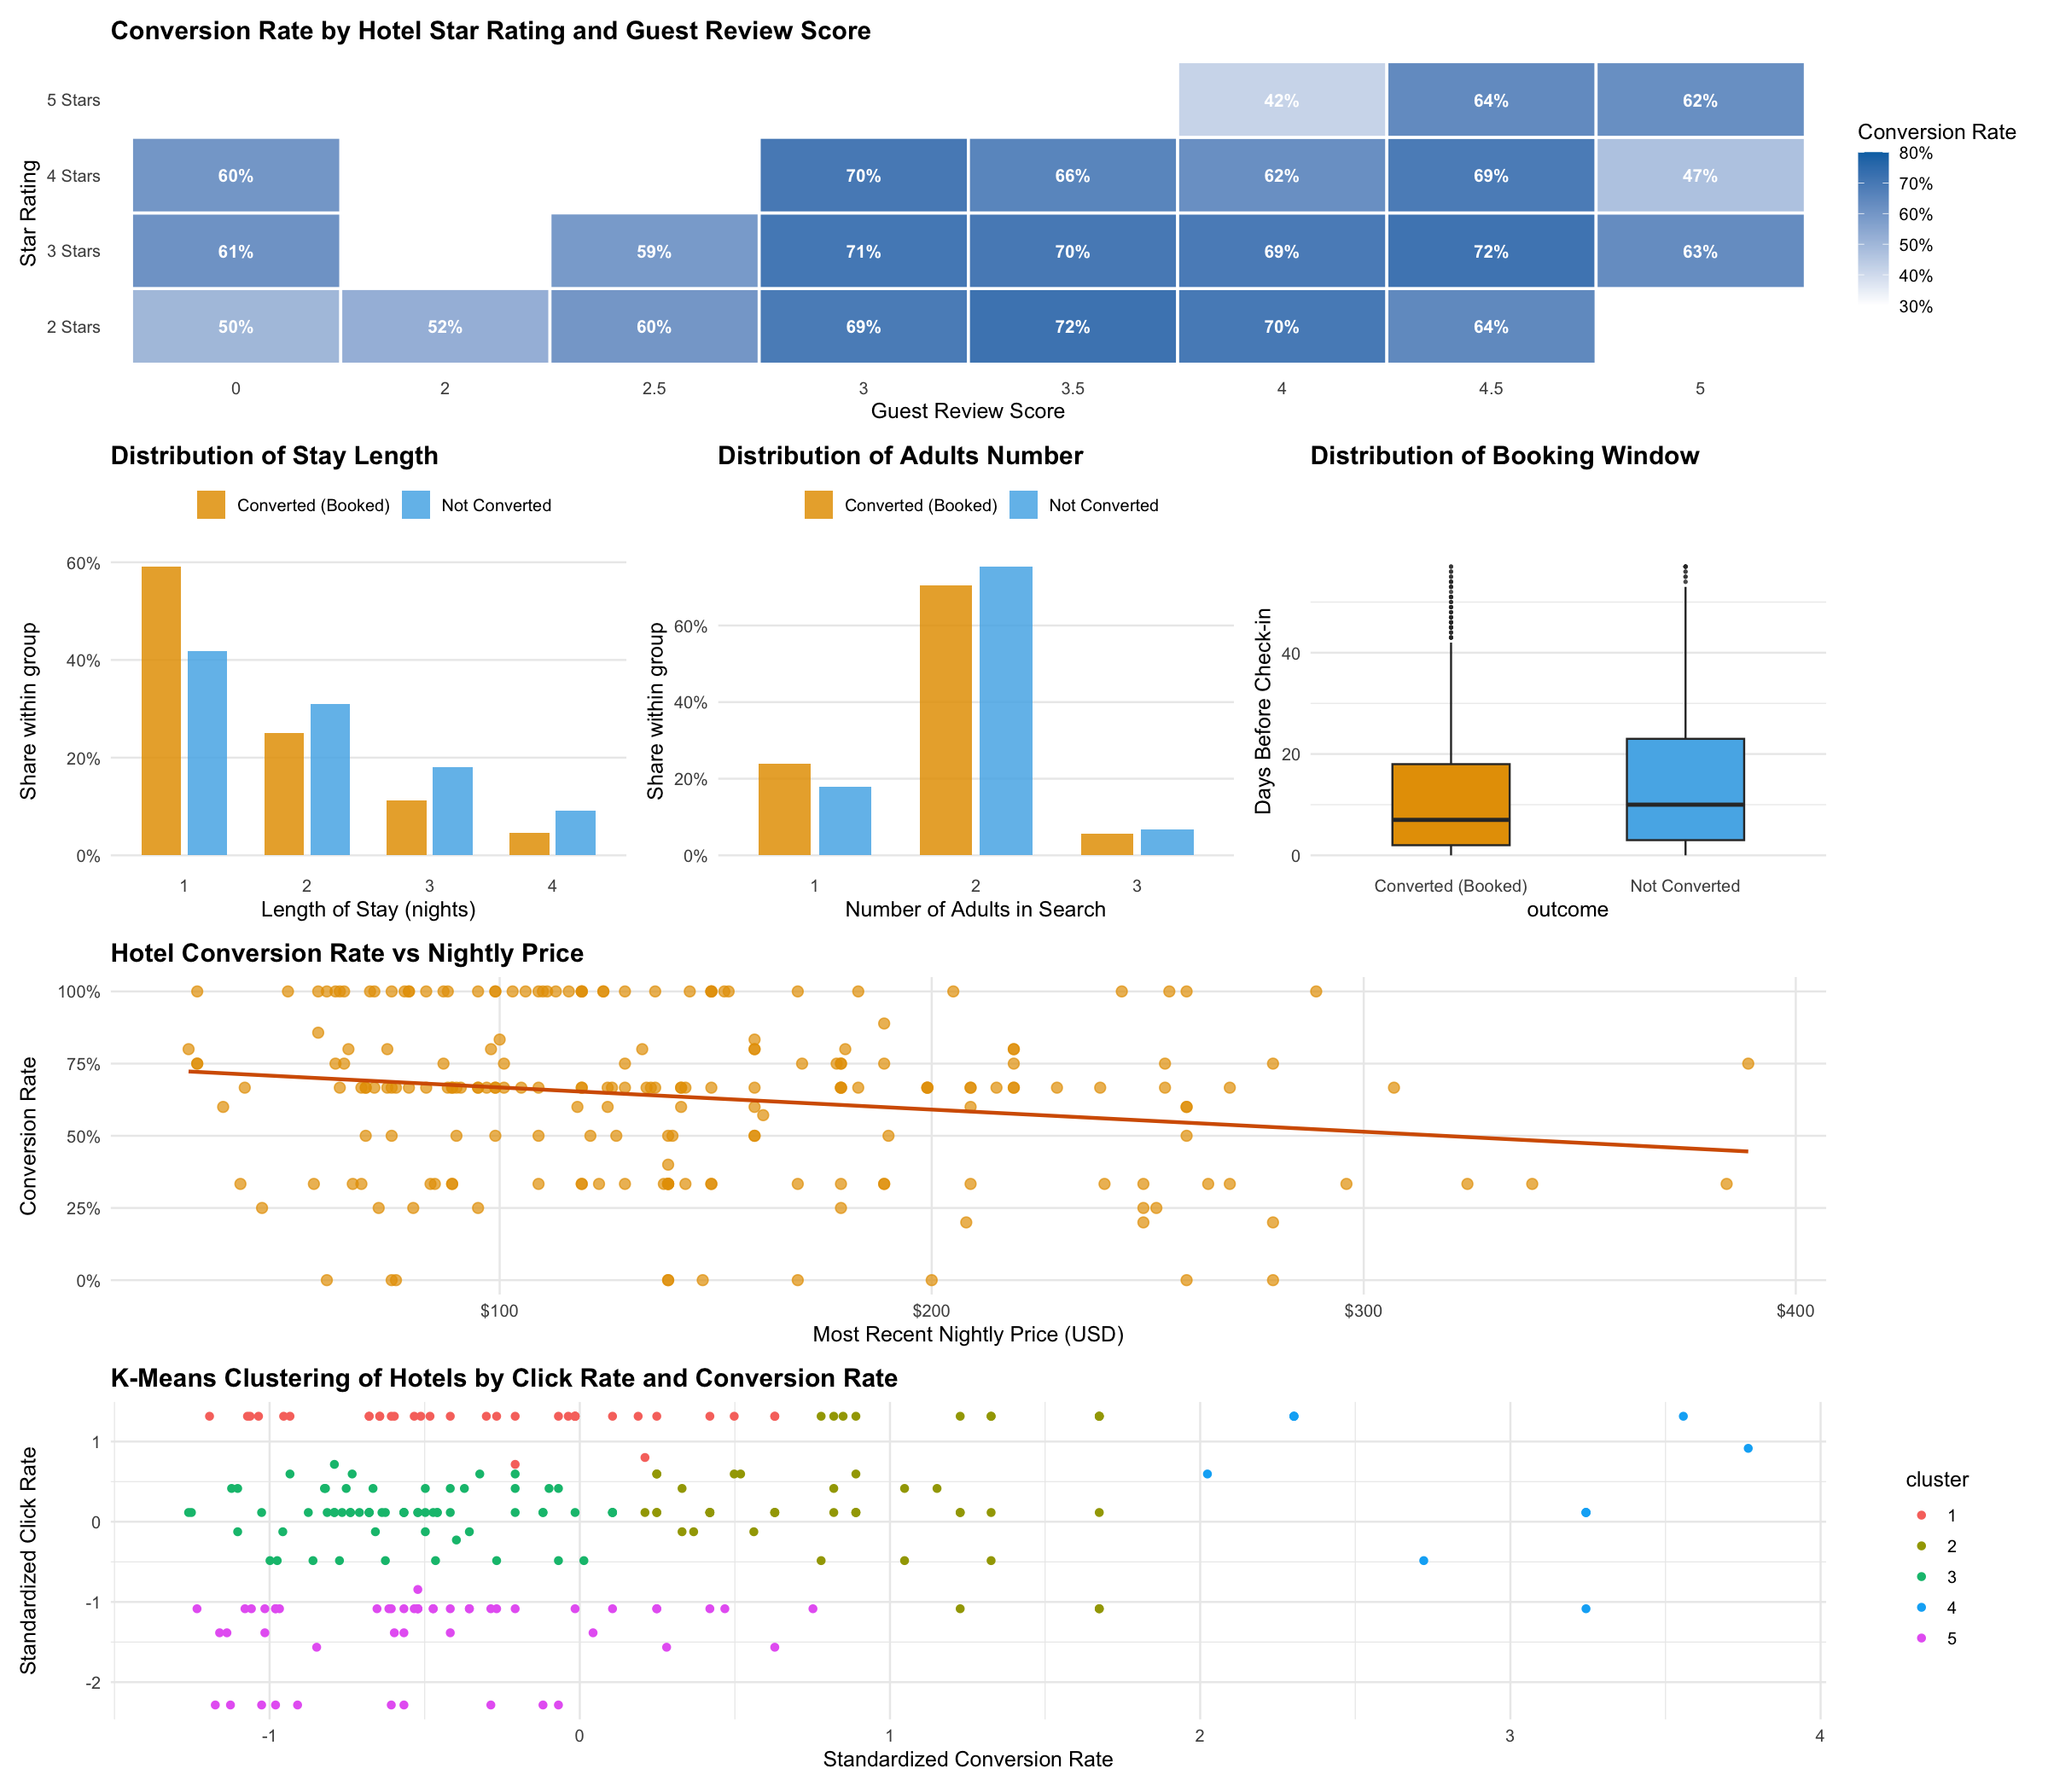

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 14, repr.plot.res = 150)

(plot_heatmap) /
(plot_los | plot_adults | plot_window) /
(plot_price) /
(plot_kmeans)

## Part B: Analytics Team Memo

## Part C: 

In [47]:
hotel_summary |>
  mutate(
    cluster = case_when(
      cluster == 1 ~ "Type 1 Hotel",
      cluster == 2 ~ "Type 2 Hotel",
      cluster == 3 ~ "Type 3 Hotel",
      cluster == 4 ~ "Type 4 Hotel",
      cluster == 5 ~ "Type 5 Hotel"
    ),
    avg_click_rate     = percent(avg_click_rate,     accuracy = 0.1),
    avg_conv_rate      = percent(avg_conv_rate,      accuracy = 0.1),
    avg_price          = dollar(avg_price,           accuracy = 1),
    avg_length_stay    = round(avg_length_stay,      1),
    avg_adults         = round(avg_adults,           1),
    avg_booking_window = round(avg_booking_window,   1),
    avg_n_shown        = round(avg_n_shown,          0)
  ) |>
  rename(
    "Hotel Type"        = cluster,
    "# Hotels"          = n_hotels,
    "Click Rate"        = avg_click_rate,
    "Conversion Rate"   = avg_conv_rate,
    "Avg. Price (USD)"  = avg_price,
    "Avg. Stay (nights)"= avg_length_stay,
    "Avg. Adults"       = avg_adults,
    "Avg. Lead Time (days)" = avg_booking_window,
    "Avg. Impressions"  = avg_n_shown
  ) |>
  knitr::kable(align = c("l", rep("r", 8)))



|Hotel Type   | # Hotels| Click Rate| Conversion Rate| Avg. Price (USD)| Avg. Stay (nights)| Avg. Adults| Avg. Lead Time (days)| Avg. Impressions|
|:------------|--------:|----------:|---------------:|----------------:|------------------:|-----------:|---------------------:|----------------:|
|Type 1 Hotel |       34|      18.5%|           99.1%|             $130|                1.7|         1.8|                  12.5|               27|
|Type 4 Hotel |       11|      69.6%|           77.5%|             $108|                1.5|         1.8|                  11.6|                6|
|Type 2 Hotel |       46|      37.2%|           72.4%|             $117|                1.7|         1.9|                  12.8|               12|
|Type 3 Hotel |       65|      14.2%|           66.3%|             $153|                1.9|         1.9|                  13.3|               38|
|Type 5 Hotel |       51|      15.6%|           25.0%|             $169|                2.0|         1.9|           